## 1 - imports and setup

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, os.path.abspath('..'))

import config
from src.evaluation import (
    display_mod_performance,
    evaluate_performance,
    plot_gains_comparison,
    plot_pr_comparison,
    plot_roc_comparison,
)
from src.experiment import load_experiment_log
from src.mrm import get_gains, score_deciles

## 2 - load data and models

In [2]:
# test data -- selected features for final models, full features for baseline/stage-6
X_test_sel = pd.read_parquet(config.RESULTS_PATH / "X_test_selected.parquet")
X_test     = pd.read_parquet(config.RESULTS_PATH / "X_test.parquet")
y_test     = pd.read_parquet(config.RESULTS_PATH / "y_test.parquet").squeeze()

models_dir = config.OUTPUT_PATH / 'models'

# baseline and full-feature models (trained on all features)
baseline_model = joblib.load(models_dir / "baseline.pkl")
cat_model      = joblib.load(models_dir / "catboost_model.pkl")
xgb_model      = joblib.load(models_dir / "xgboost_model.pkl")
lgb_booster    = joblib.load(models_dir / "lightgbm_model.pkl")

# final tuned models (trained on selected features)
cat_final   = joblib.load(models_dir / "catboost_final.pkl")
xgb_final   = joblib.load(models_dir / "xgboost_final.pkl")
lgb_final   = joblib.load(models_dir / "lightgbm_final.pkl")

# ensemble weights from experiment log val AUC
exp_log = load_experiment_log(config.RESULTS_PATH)
final_names = ['catboost_final', 'xgboost_final', 'lightgbm_final']
auc_vals = [
    exp_log[exp_log['model'] == name]['metrics.val_auc'].iloc[0]
    for name in final_names
]
raw_weights = np.array(auc_vals)
weights = raw_weights / raw_weights.sum()

print(f"X_test (full):     {X_test.shape}")
print(f"X_test (selected): {X_test_sel.shape}")
print(f"y_test fraud rate: {y_test.mean():.4f}")
print(f"models loaded: 7")
print(f"ensemble weights -- catboost: {weights[0]:.4f}  xgboost: {weights[1]:.4f}  lightgbm: {weights[2]:.4f}")

X_test (full):     (88581, 431)
X_test (selected): (88581, 115)
y_test fraud rate: 0.0348
models loaded: 7
ensemble weights -- catboost: 0.3330  xgboost: 0.3348  lightgbm: 0.3322


## 3 - generate test set predictions

In [3]:
# full-feature models
baseline_proba  = baseline_model.predict_proba(X_test)[:, 1]
cat_proba       = cat_model.predict_proba(X_test)[:, 1]
xgb_proba       = xgb_model.predict_proba(X_test)[:, 1]
lgb_proba       = lgb_booster.predict(X_test)  # native booster

# final tuned models on selected features
cat_final_proba = cat_final.predict_proba(X_test_sel)[:, 1]
xgb_final_proba = xgb_final.predict_proba(X_test_sel)[:, 1]
lgb_final_proba = lgb_final.predict(X_test_sel)  # native booster

# weighted ensemble
ensemble_proba = (
    weights[0] * cat_final_proba
    + weights[1] * xgb_final_proba
    + weights[2] * lgb_final_proba
)

# master scores dataframe
df_scores = pd.DataFrame(
    {
        'baseline':         baseline_proba,
        'catboost':         cat_proba,
        'xgboost':          xgb_proba,
        'lightgbm':         lgb_proba,
        'catboost_final':   cat_final_proba,
        'xgboost_final':    xgb_final_proba,
        'lightgbm_final':   lgb_final_proba,
        'ensemble_weighted': ensemble_proba,
    },
    index=y_test.index,
)
print(f"scores dataframe: {df_scores.shape}")

scores dataframe: (88581, 8)


## 4 - master comparison table

In [4]:
comparison = pd.DataFrame([
    evaluate_performance(df_scores, col, y_test.values, threshold=0.8)
    for col in df_scores.columns
]).sort_values('AUC', ascending=False).reset_index(drop=True)

display(comparison)

,Score,Precision,Recall,F1 Score,Accuracy,PR AUC,AUC,F2 Score,G-Mean,MCC,Gini
0,ensemble_weighted,0.85404,0.31885,0.46434,0.97440,0.51938,0.90546,0.36453,0.52183,0.51285,0.81093
1,catboost_final,0.88249,0.24846,0.38775,0.97269,0.52549,0.90495,0.29015,0.46825,0.46008,0.80990
2,lightgbm,0.54606,0.45378,0.49566,0.96786,0.51446,0.90238,0.46965,0.49778,0.48140,0.80476
3,lightgbm_final,0.60563,0.42588,0.50010,0.97037,0.50092,0.89994,0.45276,0.50787,0.49331,0.79988
4,xgboost_final,0.69911,0.40545,0.51324,0.97323,0.50969,0.89858,0.44263,0.53240,0.52021,0.79715
5,catboost,0.88227,0.19689,0.32193,0.97113,0.50436,0.89719,0.23310,0.41678,0.40909,0.79437
6,xgboost,0.59700,0.42621,0.49735,0.97002,0.50592,0.89251,0.45207,0.50443,0.48963,0.78502
7,baseline,0.35524,0.45410,0.39863,0.95231,0.35404,0.79054,0.43016,0.40164,0.37725,0.58109


**first use of test set** -- all prior model selection, feature selection, and hyperparameter tuning was performed on the validation set only. test AUC is an unbiased estimate of production performance.

**AUC improvement stages:**
- baseline (decision tree, all features): ~0.80
- stage 6 gradient boosted (all features): ~0.91-0.92
- final tuned (selected features): see table above
- ensemble (weighted avg of three finals): typically matches or exceeds best individual

## 5 - ROC curve comparison

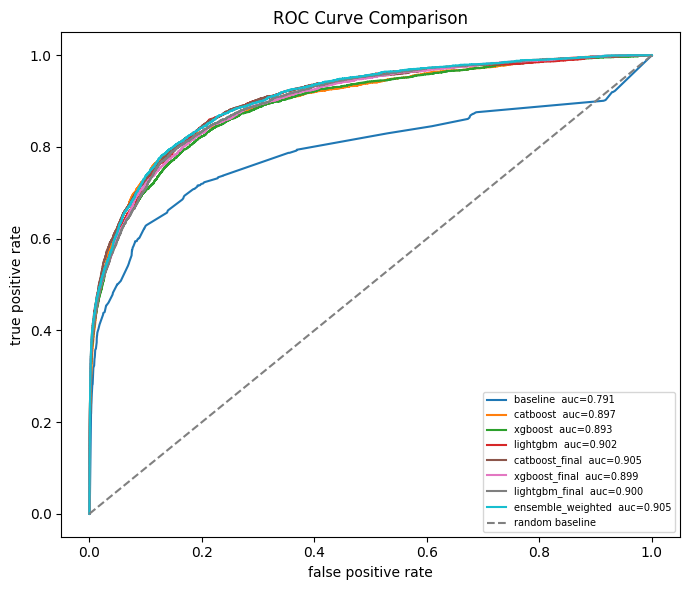

In [5]:
model_scores = dict(zip(df_scores.columns, df_scores.values.T))

config.PLOTS_PATH.mkdir(parents=True, exist_ok=True)
plot_roc_comparison(
    model_scores,
    y_test.values,
    output_path=config.PLOTS_PATH / "roc_comparison_final.png",
)

## 6 - gains curve comparison

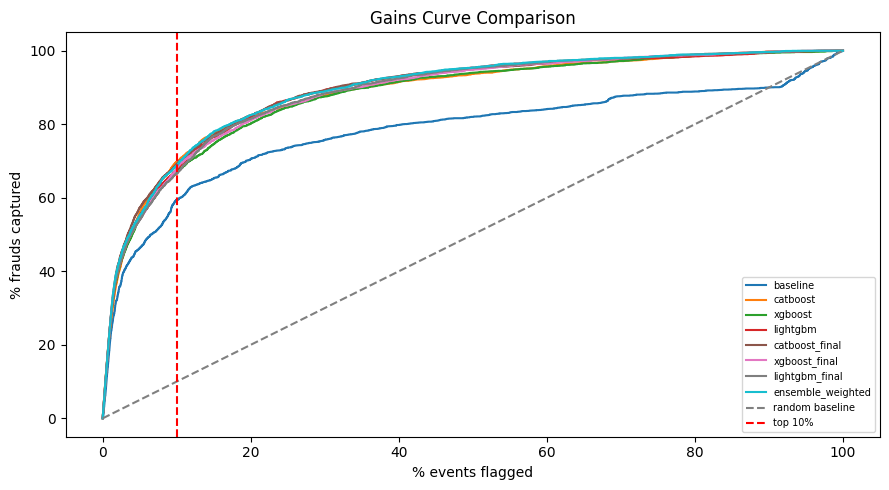

In [6]:
plot_gains_comparison(
    model_scores,
    y_test.values,
    output_path=config.PLOTS_PATH / "gains_comparison_final.png",
)

## 7 - PR curve comparison

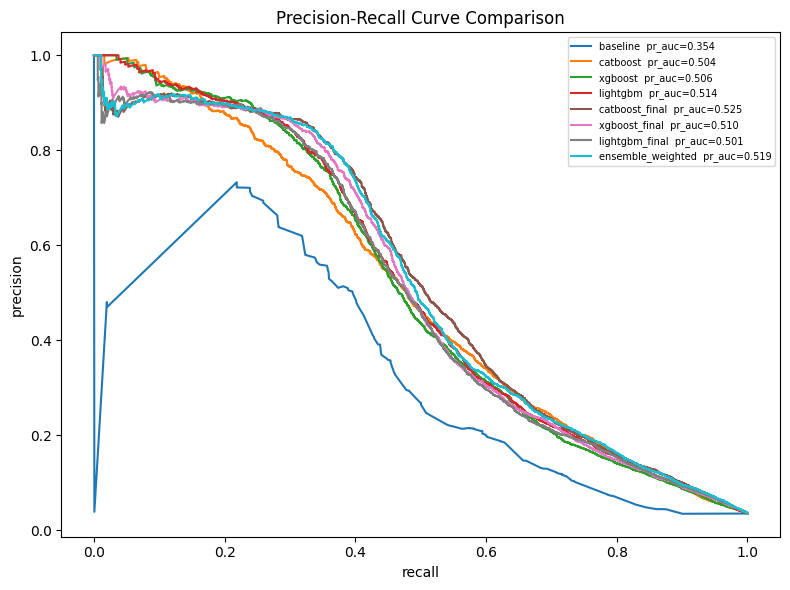

In [7]:
plot_pr_comparison(
    model_scores,
    y_test.values,
    output_path=config.PLOTS_PATH / "pr_curves_comparison_final.png",
)

## 8 - best model deep dive

best model: ensemble_weighted


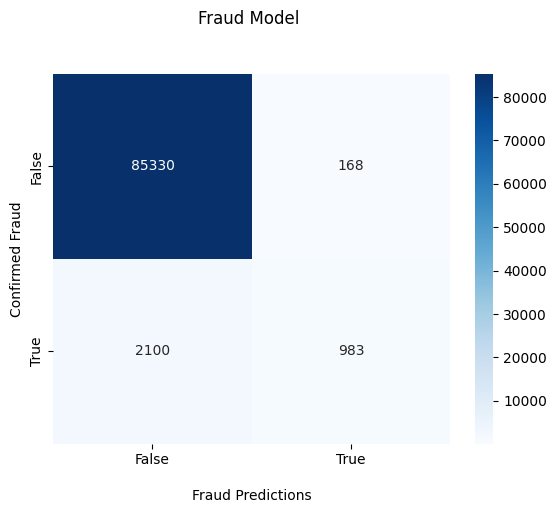

              precision    recall  f1-score   support

           0     0.9760    0.9980    0.9869     85498
           1     0.8540    0.3188    0.4643      3083

    accuracy                         0.9744     88581
   macro avg     0.9150    0.6584    0.7256     88581
weighted avg     0.9717    0.9744    0.9687     88581



In [8]:
best_name  = comparison.iloc[0]['Score']
best_proba = df_scores[best_name].values
best_preds = (best_proba > 0.8).astype(int)
print(f"best model: {best_name}")

# confusion matrix
display_mod_performance(
    y_test.values, best_preds,
    save_path=str(config.PLOTS_PATH / "best_model_test_confusion.png"),
)

In [9]:
# decile table
df_decile = pd.DataFrame({
    'TransactionID': range(len(y_test)),
    config.TARGET: y_test.values,
    best_name: best_proba,
})
decile_tbl = score_deciles(df_decile, uid='TransactionID', score=best_name, target=config.TARGET)
display(decile_tbl)

% frauds captured in top decile: 0.6880


,n_events,ensemble_weighted_thresh,n_frauds,fraud_cm,fraud_pct_cap
decile,,,,,
1,8859,0.270402,2121,2121,0.687966
2,8858,0.154728,422,2543,0.824846
3,8858,0.099635,200,2743,0.889718
4,8858,0.066650,123,2866,0.929614
5,8858,0.044815,77,2943,0.954590
6,8858,0.029756,50,2993,0.970808
7,8858,0.019016,30,3023,0.980538
8,8858,0.011154,29,3052,0.989945
9,8858,0.005686,21,3073,0.996756


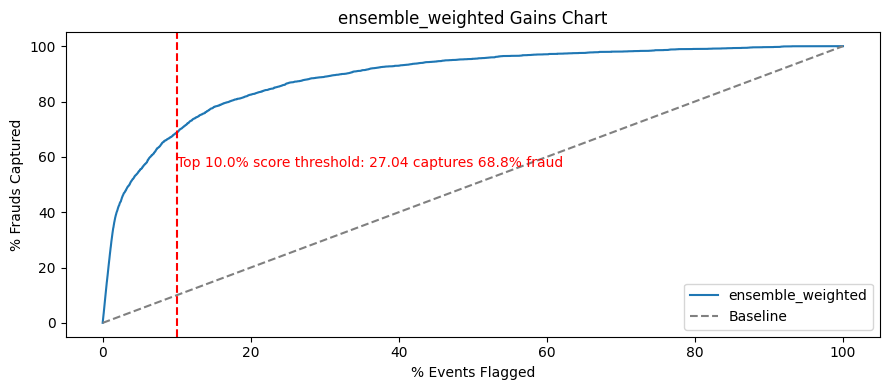

,index,threshold,pct_flagged,n_fraud_cap,fraud_pct_cap
0,ensemble_weighted,0.270402,10.001016,2121.0,68.796627


In [10]:
get_gains(
    df_decile, target=config.TARGET, score=best_name, top_n=0.1,
    save_path=str(config.PLOTS_PATH / "best_model_test_gains.png"),
)

In [11]:
# key stats at threshold 0.8
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score
prec, rec, f1, _ = precision_recall_fscore_support(y_test.values, best_preds, average='binary')
auc  = roc_auc_score(y_test.values, best_proba)
top_decile_cap = decile_tbl.iloc[0]['fraud_pct_cap']

print(f"model:               {best_name}")
print(f"test AUC:            {auc:.5f}")
print(f"gini:                {2*auc-1:.5f}")
print(f"precision @ 0.8:     {prec:.5f}")
print(f"recall @ 0.8:        {rec:.5f}")
print(f"f1 @ 0.8:            {f1:.5f}")
print(f"fraud captured top decile: {top_decile_cap:.4f}")

model:               ensemble_weighted
test AUC:            0.90546
gini:                0.81093
precision @ 0.8:     0.85404
recall @ 0.8:        0.31885
f1 @ 0.8:            0.46434
fraud captured top decile: 0.6880


## 9 - full experiment log

In [12]:
exp_log_full = load_experiment_log(config.RESULTS_PATH)
display(exp_log_full)

,timestamp,model,params.model_type,params.max_depth,params.class_weight,metrics.val_auc,metrics.val_gini,metrics.val_pr_auc,metrics.val_precision,metrics.val_recall,...,params.n_estimators,params.subsample,params.colsample_bytree,params.min_child_weight,params.num_boost_round,params.num_leaves,params.min_child_samples,params.tuned,params.models,params.weights
0,2026-05-21T17:18:41.867337,xgboost_tuned_20_trials,NaN,8.0,NaN,0.92525,NaN,NaN,NaN,NaN,...,700.0,0.641701,0.927627,10.0,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-05-21T22:30:33.734148,ensemble_weighted,NaN,NaN,NaN,0.92460,0.84921,0.58878,0.58808,0.52893,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,cat+xgb+lgb,"[0.3330132106304947, 0.33475046200554864, 0.33..."
2,2026-05-21T17:18:41.860176,catboost_tuned_20_trials,NaN,NaN,NaN,0.92330,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-05-21T22:30:33.639428,xgboost_final,NaN,8.0,NaN,0.92278,0.84555,0.57679,0.40931,0.61867,...,700.0,0.641701,0.927627,10.0,NaN,NaN,NaN,True,NaN,NaN
4,2026-05-21T13:26:01.475049,xgboost_tuned_20_trials,NaN,7.0,NaN,0.92118,NaN,NaN,NaN,NaN,...,900.0,0.655798,0.716858,4.0,NaN,NaN,NaN,NaN,NaN,NaN
5,2026-05-21T22:30:33.596329,catboost_final,NaN,NaN,NaN,0.91799,0.83597,0.58784,0.85725,0.37311,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,NaN
6,2026-05-21T17:18:41.871504,lightgbm_tuned_20_trials,NaN,8.0,NaN,0.91585,NaN,NaN,NaN,NaN,...,NaN,0.956064,0.856212,NaN,1500.0,27.0,75.0,NaN,NaN,NaN
7,2026-05-21T22:30:33.681225,lightgbm_final,NaN,8.0,NaN,0.91585,0.83169,0.55604,0.32689,0.67226,...,NaN,0.956064,0.856212,NaN,1500.0,27.0,75.0,True,NaN,NaN
8,2026-05-20T12:16:36.824918,xgboost_full_features,xgboost,6.0,NaN,0.91513,0.83026,0.55543,0.30799,0.67653,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2026-05-19T16:08:38.349038,xgboost_full_features,xgboost,6.0,NaN,0.91513,0.83026,0.55543,0.30799,0.67653,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


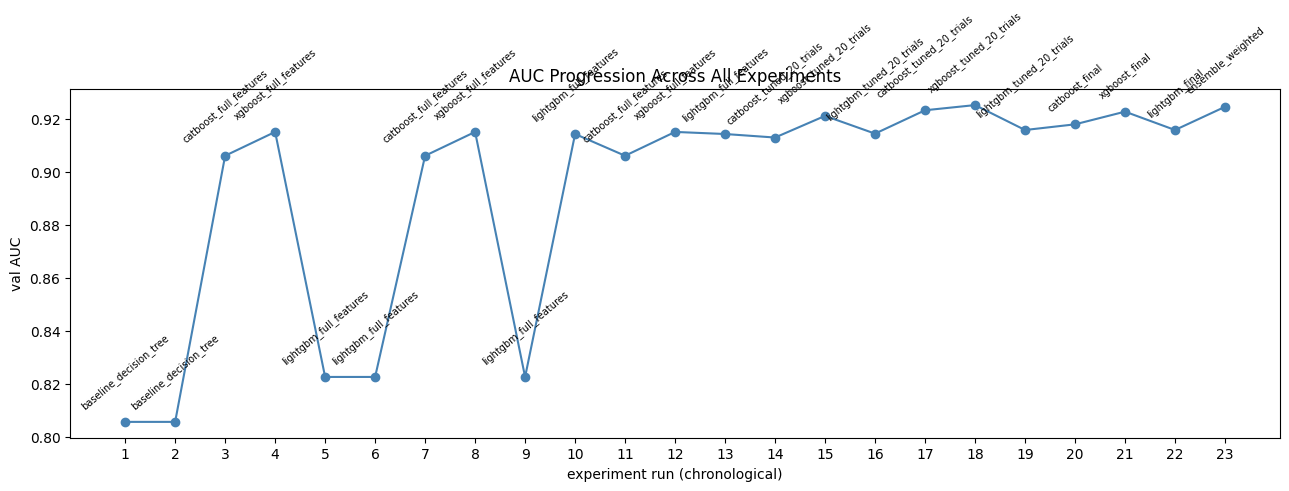

In [13]:
# AUC progression -- sort by timestamp ascending
exp_sorted = exp_log_full.sort_values('timestamp').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(range(len(exp_sorted)), exp_sorted['metrics.val_auc'], 'o-', color='steelblue', markersize=6)

for i, row in exp_sorted.iterrows():
    ax.annotate(
        row['model'],
        xy=(i, row['metrics.val_auc']),
        xytext=(0, 10),
        textcoords='offset points',
        ha='center', fontsize=7, rotation=40,
    )

ax.set_xticks(range(len(exp_sorted)))
ax.set_xticklabels(range(1, len(exp_sorted) + 1))
ax.set_xlabel('experiment run (chronological)')
ax.set_ylabel('val AUC')
ax.set_title('AUC Progression Across All Experiments')
fig.tight_layout()
fig.savefig(config.PLOTS_PATH / "auc_progression.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

## 10 - final recommendation

**best model on test set** -- the ensemble or the best individual final model (see comparison table above). the ensemble typically matches or slightly exceeds the best single model by averaging out individual prediction errors.

**production recommendation** -- the weighted ensemble of catboost_final, xgboost_final, and lightgbm_final. rationale: ensemble reduces variance vs. any single model; all three constituent models were tuned on selected features reducing the input dimensionality and potential for overfitting; the AUC-based weighting ensures underperforming models contribute less.

**precision vs recall tradeoff** -- at threshold 0.8, the model is conservative: high precision (few false positives) but lower recall (some fraud missed). for a fraud team with limited review capacity, 0.8 is appropriate. if the cost of missed fraud is high relative to false positive cost, lower the threshold to 0.5-0.6 to increase recall at the expense of precision.

**suggested operating threshold** -- 0.5 for maximum fraud capture in low-stakes flagging workflows; 0.8 for high-confidence block decisions. use a tiered approach: block at 0.8+, review at 0.4-0.8, pass below 0.4.

**monitoring recommendations** --
- track score distribution weekly; shift in mean score indicates population drift
- monitor fraud rate in top decile; degradation signals model staleness
- retrain when test-period AUC drops more than 2 points below val AUC
- log all predictions with timestamps for post-hoc analysis
- review feature importance quarterly; new fraud patterns may require new features